In [10]:
from pathlib import Path 
import cv2
import matplotlib.pyplot as plt
import numpy as np


Put screw images into array

In [11]:
DATA_DIR = Path("../data")
images = []
for path in sorted(DATA_DIR.glob("*.jpg")):
    image = cv2.imread(str(path))
    images.append(image)

Crop images

In [12]:
cropped_images = [image[1110:1600, 1900:2100] for image in images]

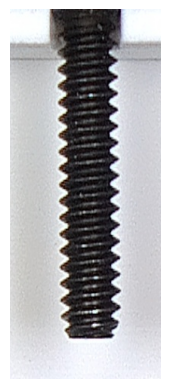

In [13]:
plt.imshow(cv2.cvtColor(cropped_images[6], cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
# plt.imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RBG))

Use Segmentation to estimate screw geometry

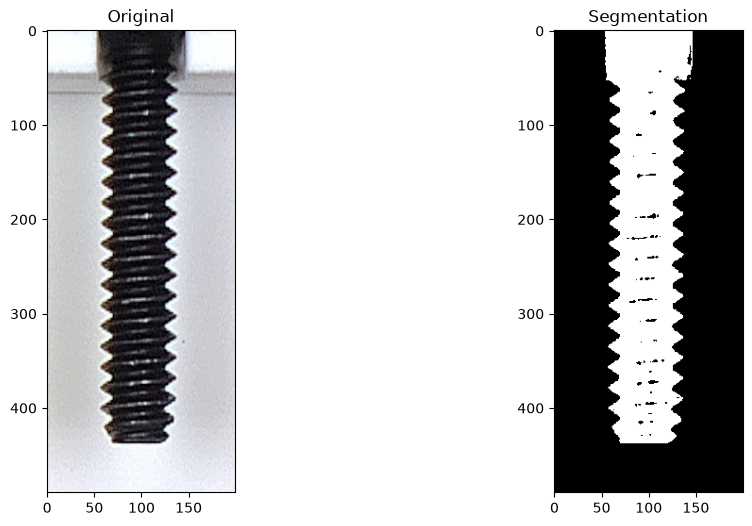

In [24]:
my_image = cropped_images[30]

gray = cv2.cvtColor(my_image, cv2.COLOR_BGR2GRAY)

_, mask = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU

)

plt.figure(figsize=(12,6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(my_image, cv2.COLOR_BGR2RGB))
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Segmentation")

plt.show()

In [54]:
y, x = np.where(mask > 0)

points = np.column_stack((x, y))

mean = points.mean(axis=0)
centered = points - mean

cov = np.cov(centered, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(cov)
principal_axis = eigenvectors[:, np.argmax(eigenvalues)]



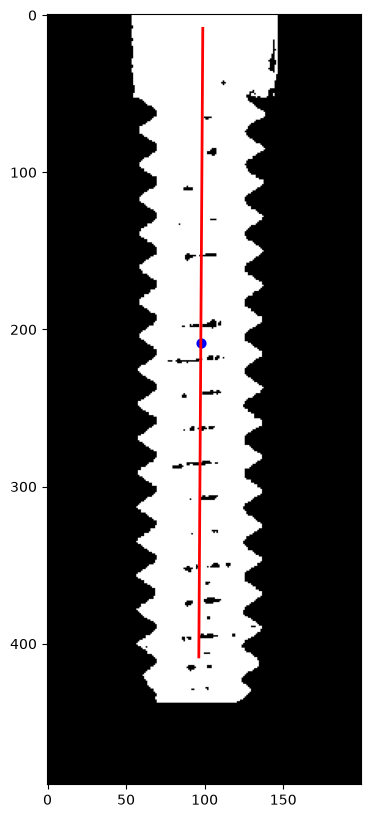

In [26]:
vx, vy = principal_axis
cx, cy = mean

length = 200

plt.figure(figsize=(6,10))
plt.imshow(mask, cmap="gray")
plt.plot(
    [cx-length*vx, cx+length*vx],
    [cy-length*vy, cy+length*vy],
    "r-",
    linewidth=2
)
plt.scatter(cx,cy, color="blue", s=40)

In [27]:
angle = np.degrees(np.arctan2(vy, vx))
angle = angle % 180
angle = angle - 90

height, width = my_image.shape[:2]

rotation_matrix = cv2.getRotationMatrix2D(
    center=(cx, cy),
    angle=angle,
    scale=1.0
)


In [28]:
rotated_image = cv2.warpAffine(
    my_image,
    rotation_matrix,
    (width, height)
)

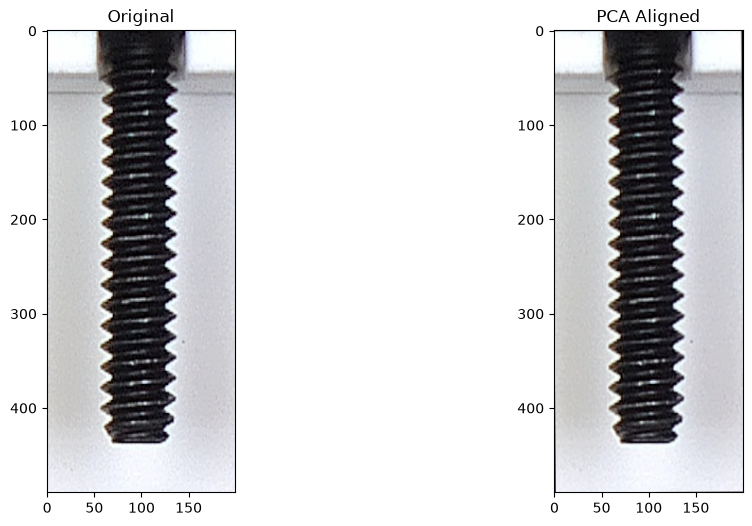

In [29]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(my_image, cv2.COLOR_BGR2RGB))
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB))
plt.title("PCA Aligned")

plt.show()

Detected bottom: 434
Crop bottom: 444


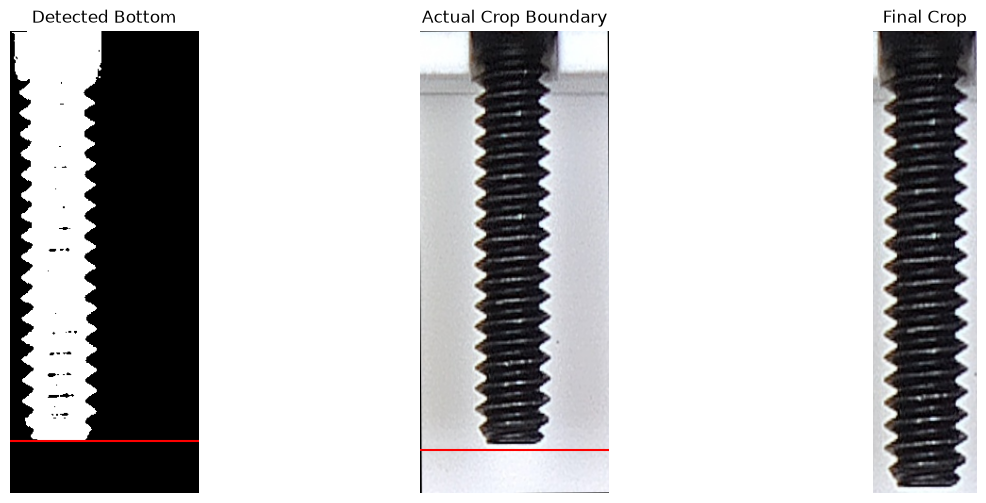

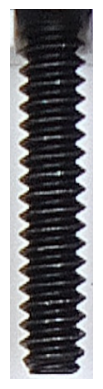

In [70]:
height, width = rotated_image.shape[:2]

aligned_mask = cv2.warpAffine(
    mask,
    rotation_matrix,
    (width, height),
    flags=cv2.INTER_NEAREST
)
y, x = np.where(aligned_mask > 0)

crop_width = 100
margin = 10

bottom_y = y.max()

x1 = int(cx - crop_width / 2)
x2 = int(cx + crop_width / 2)
y1 = int(bottom_y + margin)

final_processed_image = rotated_image[:y1, x1:x2]
plt.imshow(cv2.cvtColor(final_processed_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [71]:
def preprocess(my_image):
    gray = cv2.cvtColor(my_image, cv2.COLOR_BGR2GRAY)

    _, mask = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU

    )
    y, x = np.where(mask > 0)

    points = np.column_stack((x, y))

    mean = points.mean(axis=0)
    centered = points - mean

    cov = np.cov(centered, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    principal_axis = eigenvectors[:, np.argmax(eigenvalues)]

    vx, vy = principal_axis
    cx, cy = mean
    angle = np.degrees(np.arctan2(vy, vx))
    angle = angle % 180
    angle = angle - 90

    height, width = my_image.shape[:2]

    rotation_matrix = cv2.getRotationMatrix2D(
        center=(cx, cy),
        angle=angle,
        scale=1.0
    )
    rotated_image = cv2.warpAffine(
                        my_image,
                        rotation_matrix,
                        (width, height)
                        )
    height, width = rotated_image.shape[:2]

    aligned_mask = cv2.warpAffine(
        mask,
        rotation_matrix,
        (width, height),
        flags=cv2.INTER_NEAREST
    )
    y, x = np.where(aligned_mask > 0)

    crop_width = 100
    margin = 10

    bottom_y = y.max()

    x1 = int(cx - crop_width / 2)
    x2 = int(cx + crop_width / 2)
    y1 = int(bottom_y + margin)

    return rotated_image[:y1, x1:x2]



In [72]:
processed_images = [preprocess(image) for image in cropped_images]

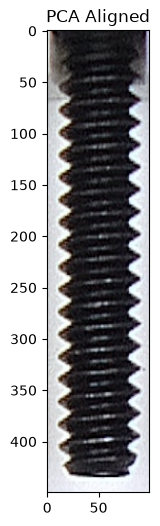

In [40]:
plt.figure(figsize=(12, 6))




plt.imshow(cv2.cvtColor(processed_images[10], cv2.COLOR_BGR2RGB))
plt.title("PCA Aligned")

plt.show()

In [41]:
train_dir = Path("../data/train")
train_dir.mkdir(parents=True, exist_ok=True)

for i, image in enumerate(processed_images):
    cv2.imwrite(str(train_dir / f"screw_{i:04d}.png"), image)

NN training starts here 

In [42]:
import os

os.environ["TQDM_DISABLE"] = "1"
os.environ["TERM"] = "dumb"

In [43]:
import torch
from anomalib.models import Patchcore
from anomalib.engine import Engine

print("CUDA availabe:", torch.cuda.is_available())

model = Patchcore(
    backbone="resnet18",
    layers=["layer2", "layer3"],
    coreset_sampling_ratio=0.1
)

engine = Engine()

CUDA availabe: True


In [44]:
from anomalib.data import Folder 
from anomalib.data.utils import TestSplitMode

datamodule = Folder(
    name="screws",
    root="../data",
    normal_dir="train",
    test_split_mode=TestSplitMode.SYNTHETIC,
    train_batch_size = 8,
    eval_batch_size=8,
    num_workers=0
)

engine.fit(
    model=model,
    datamodule=datamodule
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/savanna/github/ScrewMachine/.venv/lib/python3.12/site-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │  2.8 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘

Trainable params: 2.8 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.8 M                                                                                                
Total estimated model params size (MB): 11.131                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 69                                                                                           
Total FLOPs: 0

/home/savanna/github/ScrewMachine/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/savanna/github/ScrewMachine/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/savanna/github/ScrewMachine/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
/home/savanna/github/ScrewMachine/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
/home/savanna/github/ScrewMachine/.venv/lib/python3.12/site-packages/lightning/pytorch/loops/fit_loop.py:538: F

In [45]:
datamodule.setup(stage="test")

test_loader = datamodule.test_dataloader()

batch = next(iter(test_loader))

In [46]:
print(batch.image.shape)
print(batch.gt_label)

torch.Size([8, 3, 256, 256])
tensor([False, False, False, False,  True,  True,  True,  True])


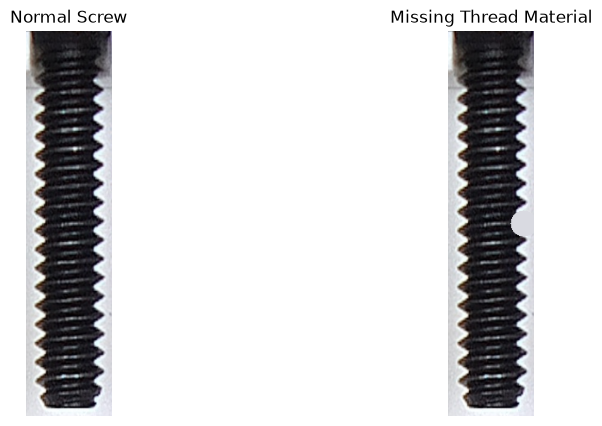

In [79]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Start with a preprocessed screw
original = preprocess(processed_images[3])
defective = original.copy()

h, w = original.shape[:2]

# Find the screw using a threshold
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
_, mask = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Choose a point on the right edge of the screw
y = h // 2
row = np.where(mask[y] > 0)[0]
x = row.max()

# Simulate a missing chunk of threads
radius = 15

# Estimate background color
background = np.median(
    original[:, -10:, :],
    axis=(0, 1)
).astype(np.uint8)

cv2.circle(
    defective,
    (int(x), int(y)),
    radius,
    background.tolist(),
    -1
)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
axes[0].set_title("Normal Screw")

axes[1].imshow(cv2.cvtColor(defective, cv2.COLOR_BGR2RGB))
axes[1].set_title("Missing Thread Material")

for ax in axes:
    ax.axis("off")

plt.show()

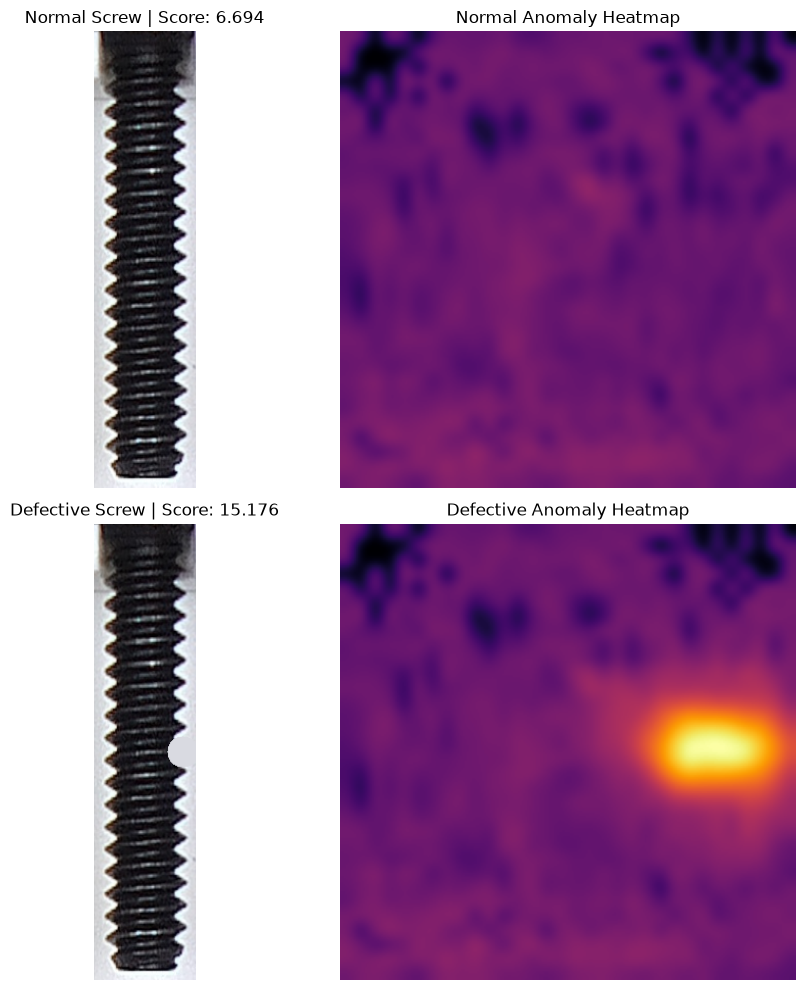

In [80]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

model.eval()
device = next(model.parameters()).device

def predict(image):
    # BGR -> RGB
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convert to tensor [0, 1]
    tensor = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255.0

    # Apply the model's actual training preprocessing
    tensor = model.pre_processor.transform(tensor)

    # Add batch dimension and move to GPU
    tensor = tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        prediction = model.model(tensor)

    score = prediction.pred_score.item()
    heatmap = prediction.anomaly_map.squeeze().cpu().numpy()

    return rgb, score, heatmap


# Test both screws
results = [
    ("Normal", original),
    ("Defective", defective)
]

predictions = [predict(image) for _, image in results]

# Use the SAME color scale for both heatmaps
vmin = min(p[2].min() for p in predictions)
vmax = max(p[2].max() for p in predictions)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for i, ((name, _), (image, score, heatmap)) in enumerate(
    zip(results, predictions)
):
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"{name} Screw | Score: {score:.3f}")

    axes[i, 1].imshow(heatmap, cmap="inferno", vmin=vmin, vmax=vmax)
    axes[i, 1].set_title(f"{name} Anomaly Heatmap")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [51]:
print("Dataset attributes:")
print([x for x in dir(datamodule.train_data) if "transform" in x or "augment" in x])

print("\nDatamodule attributes:")
print([x for x in dir(datamodule) if "transform" in x or "augment" in x])

print("\nModel preprocessing:")
print(model.pre_processor)

Dataset attributes:
['augmentations']

Datamodule attributes:
['_update_augmentations', '_update_subset_augmentations', 'test_augmentations', 'train_augmentations', 'val_augmentations']

Model preprocessing:
PreProcessor(
  (transform): Compose(
        Resize(size=[256, 256], interpolation=bilinear, antialias=True)
        Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
  )
  (export_transform): Compose(
        Resize(size=[256, 256], interpolation=bilinear, antialias=False)
        Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
  )
)
